# Waste Segregation Using CNN Classification
## 1. Project Objective
A Google Colab project for folder-based waste classification using a simple CNN. All figures, tables, and conclusions are generated from the supplied data; no result is pre-filled.

## 2. Import Libraries
TensorFlow/Keras trains the CNN; scikit-learn provides stratification, metrics, and cross-validation.

In [1]:
import numpy as np
import os,gc,random
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers,models,regularizers
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
from sklearn.model_selection import train_test_split,StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report
print("TensorFlow version:",tf.__version__)
print("GPU available:",tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Set Random Seeds
Fixed seeds improve reproducibility, although GPU calculations can have small session-to-session differences.

## 4. Download Public Dataset
No Google Drive account or mount permission is needed. This notebook downloads a larger public Organic-versus-Recyclable waste dataset directly into the Colab runtime.

In [2]:
SEED=42
random.seed(SEED);np.random.seed(SEED);tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid")
!wget -q --show-progress https://www.kaggle.com/api/v1/datasets/download/sujaykapadnis/cnn-waste-classification-image-dataset -O waste_dataset.zip
!unzip -q -o waste_dataset.zip -d /content/waste_data
!find /content/waste_data -type d | head -20

waste_dataset.zip   100%[===================>] 212.38M  17.7MB/s    in 13s     
/content/waste_data
/content/waste_data/organic
/content/waste_data/organic/organic
/content/waste_data/recyclable
/content/waste_data/recyclable/recyclable


## 5. Load Dataset
Change the path below. The expected form is a dataset directory containing one folder per class. Class names and count are detected automatically.

## 6. Dataset Exploration

In [3]:
DATASET_PATH="/content/waste_data"
IMG_SIZE=(128,128);BATCH_SIZE=32;EPOCHS=50;PATIENCE=5
root=Path(DATASET_PATH); exts={".jpg",".jpeg",".png",".bmp",".gif",".webp"}
if not root.exists(): raise FileNotFoundError("Dataset was not found. Re-run the public dataset download cell, then check the printed folders and update DATASET_PATH if needed.")
def is_dataset_folder(folder):
 children=[p for p in folder.iterdir() if p.is_dir()]
 # Class images may be one level deeper. Reject wrapper archives whose child
 # folder names only differ by letter case, such as duplicate extracted copies.
 unique_names=len({p.name.lower() for p in children})==len(children)
 return unique_names and sum(any(f.is_file() and f.suffix.lower() in exts for f in child.rglob("*")) for child in children)>=2
if not is_dataset_folder(root):
 candidates=[p for p in root.rglob("*") if p.is_dir() and is_dataset_folder(p)]
 if not candidates: raise ValueError("Could not find a folder containing image class folders after download.")
 root=max(candidates,key=lambda p:sum(1 for f in p.rglob("*") if f.is_file() and f.suffix.lower() in exts))
print("Using dataset folder:",root)
dirs=sorted(x for x in root.iterdir() if x.is_dir() and not x.name.startswith("."))
if len(dirs)<2: raise ValueError("Need at least two class folders.")
class_names=[x.name for x in dirs]; mapping={x:i for i,x in enumerate(class_names)}
rows=[(str(f),d.name,mapping[d.name]) for d in dirs for f in d.rglob("*") if f.is_file() and f.suffix.lower() in exts]
df=pd.DataFrame(rows,columns=["filepath","class","class_id"])
def size(x):
 try:
  with Image.open(x) as im:return im.size
 except:return None
sizes=df.filepath.map(size); df=df.loc[sizes.notna()].copy(); sizes=sizes.dropna()
if df.empty: raise ValueError("No readable images found.")
counts=df["class"].value_counts().reindex(class_names)
print("Number of images:",len(df));print("Number of classes:",len(class_names));print("Class names:",class_names)
print("Min dimensions:",(min(x[0] for x in sizes),min(x[1] for x in sizes)))
print("Max dimensions:",(max(x[0] for x in sizes),max(x[1] for x in sizes)))
display(df.head());display(pd.DataFrame({"class":class_names,"images":counts.values}))

Using dataset folder: /content/waste_data
Number of images: 24705
Number of classes: 2
Class names: ['organic', 'recyclable']
Min dimensions: (51, 69)
Max dimensions: (1460, 1500)


,filepath,class,class_id
0,/content/waste_data/organic/organic/organic_01...,organic,0
1,/content/waste_data/organic/organic/organic_00...,organic,0
2,/content/waste_data/organic/organic/organic_00...,organic,0
3,/content/waste_data/organic/organic/organic_00...,organic,0
4,/content/waste_data/organic/organic/organic_00...,organic,0


,class,images
0,organic,13880
1,recyclable,10825


## 7. Class Distribution
Graph 1 shows number of images per waste class. The printed conclusion uses the observed largest-to-smallest ratio; it is not assumed in advance.

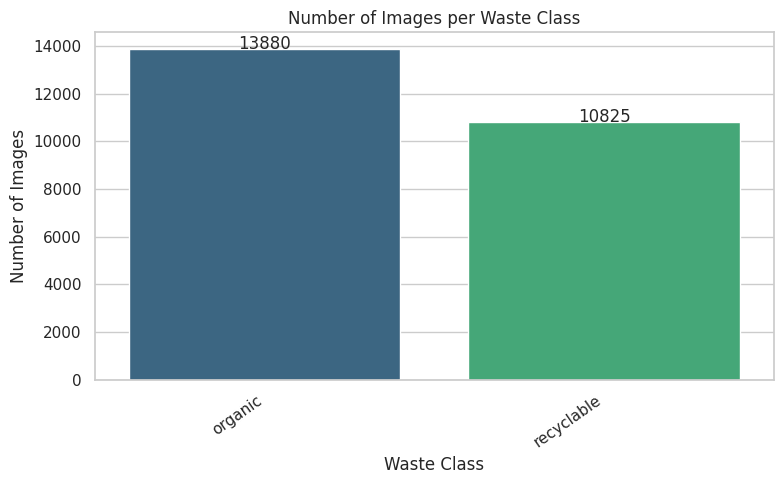

Largest/smallest ratio: 1.28
Not significantly imbalanced by the 1.5 ratio rule.


In [4]:
plt.figure(figsize=(max(8,len(class_names)),5))
ax=sns.barplot(x=counts.index,y=counts.values,hue=counts.index,palette="viridis",legend=False)
plt.title("Number of Images per Waste Class");plt.xlabel("Waste Class");plt.ylabel("Number of Images");plt.xticks(rotation=35,ha="right")
for b,v in zip(ax.patches,counts.values):ax.annotate(str(v),(b.get_x()+b.get_width()/2,v),ha="center")
plt.tight_layout()
import os; os.makedirs("figures", exist_ok=True); plt.savefig("figures/class_distribution.png", dpi=200, bbox_inches="tight"); plt.show()
imbalance_ratio=counts.max()/counts.min();imbalanced=imbalance_ratio>=1.5
print("Largest/smallest ratio:",round(imbalance_ratio,2))
print("Significantly imbalanced; class weights will be used." if imbalanced else "Not significantly imbalanced by the 1.5 ratio rule.")

## 8. Sample Images
Representative images verify labels before training.

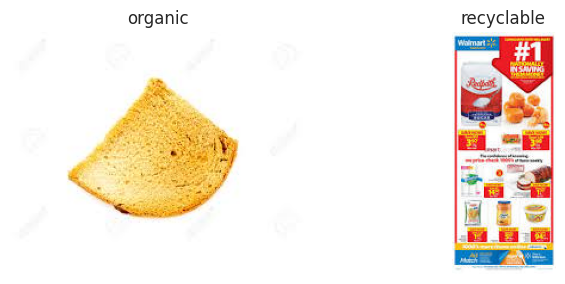

In [5]:
cols=min(4,len(class_names));rows=int(np.ceil(len(class_names)/cols))
fig,axs=plt.subplots(rows,cols,figsize=(4*cols,3*rows));axs=np.asarray(axs).reshape(-1)
for ax,name in zip(axs,class_names):
 with Image.open(df.loc[df["class"]==name,"filepath"].iloc[0]) as im:ax.imshow(im.convert("RGB"))
 ax.set_title(name);ax.axis("off")
for ax in axs[len(class_names):]:ax.axis("off")
plt.tight_layout()
import os; os.makedirs("figures", exist_ok=True); plt.savefig("figures/sample_images.png", dpi=200, bbox_inches="tight"); plt.show()

## 9. Train / Validation / Test Split
A stratified 70/15/15-style split preserves class proportions where practical. Test data is isolated before validation selection.

## 10. Class Imbalance Analysis
Accuracy can conceal poor minority-class performance. Inverse-frequency weights are applied only if actual counts meet the stated imbalance rule.

In [6]:
if df.class_id.value_counts().min()<7:raise ValueError("At least 7 images per class are required for this split and 5-fold CV.")
dev_df,test_df=train_test_split(df,test_size=.15,stratify=df.class_id,random_state=SEED)
train_df,val_df=train_test_split(dev_df,test_size=.1765,stratify=dev_df.class_id,random_state=SEED)
print("Total images:",len(df));print("Training images:",len(train_df));print("Validation images:",len(val_df));print("Testing images:",len(test_df))
display(pd.DataFrame({"Train":train_df["class"].value_counts(),"Validation":val_df["class"].value_counts(),"Test":test_df["class"].value_counts()}).reindex(class_names).fillna(0).astype(int))
cw=None
if imbalanced:
 w=compute_class_weight("balanced",classes=np.arange(len(class_names)),y=train_df.class_id);cw={int(i):float(x) for i,x in enumerate(w)}
print("Class weights:",cw if cw else "not used")

Total images: 24705
Training images: 17292
Validation images: 3707
Testing images: 3706


,Train,Validation,Test
class,,,
organic,9715,2083,2082
recyclable,7577,1624,1624


Class weights: not used


## 11. Image Preprocessing
Images are RGB-decoded, resized to 128 by 128, rescaled to 0 to 1, and streamed in batches.

## 12. Data Augmentation
Light flip, rotation, and zoom are used only on training images to improve generalization without contaminating validation or testing.

In [7]:
AUTO=tf.data.AUTOTUNE
def decode(p,y):
 x=tf.io.decode_image(tf.io.read_file(p),channels=3,expand_animations=False);x.set_shape([None,None,3])
 return tf.cast(tf.image.resize(x,IMG_SIZE),tf.float32)/255.,y
def make_ds(frame,train=False):
 d=tf.data.Dataset.from_tensor_slices((frame.filepath.to_numpy(),frame.class_id.to_numpy(np.int32)))
 if train:d=d.shuffle(len(frame),seed=SEED)
 return d.map(decode,num_parallel_calls=AUTO).batch(BATCH_SIZE).prefetch(AUTO)
aug=keras.Sequential([layers.RandomFlip("horizontal"),layers.RandomRotation(.15),layers.RandomZoom(.15),layers.RandomContrast(.10)])
train_ds,val_ds,test_ds=make_ds(train_df,True),make_ds(val_df),make_ds(test_df)

## 13. CNN Architecture
The intentionally simple architecture is Conv2D, pooling repeated three times, Flatten, a 128-unit Dense layer, optional Dropout, and output. It is appropriate to explain in a viva.

## 14. Dropout
Dropout randomly disables dense activations during fitting to reduce co-adaptation and overfitting.

## 15. L1 / Lasso Regularization
L1 is Lasso in this neural-network context: an absolute-weight penalty that can encourage sparse weights.

## 16. L2 / Ridge Regularization
L2 is Ridge in this neural-network context: a squared-weight penalty that discourages overly large weights. They are not separate techniques here.

In [8]:
def build(reg=None,drop=False):
 m=models.Sequential([layers.Input(shape=(*IMG_SIZE,3)),aug])
 for f in (32,64,128):m.add(layers.Conv2D(f,3,padding="same",activation="relu",kernel_regularizer=reg));m.add(layers.BatchNormalization());m.add(layers.MaxPooling2D())
 m.add(layers.GlobalAveragePooling2D());m.add(layers.Dense(128,activation="relu",kernel_regularizer=reg))
 if drop:m.add(layers.Dropout(.3))
 m.add(layers.Dense(len(class_names),activation="softmax"))
 m.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"]);return m
build().summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,914 (433.26 KB)

 Trainable params: 110,466 (431.51 KB)

 Non-trainable params: 448 (1.75 KB)

## 17. Model Training
Baseline, Dropout, L1/Lasso, and L2/Ridge models use the same architecture otherwise. Validation accuracy selects the model; test metrics are not used for selection.

## 18. Early Stopping

In [9]:
specs={"Baseline":(None,False),"Dropout":(None,True),"L1 / Lasso":(regularizers.l1(1e-5),False),"L2 / Ridge":(regularizers.l2(1e-4),False)}
runs={}
for name,spec in specs.items():
 tf.keras.backend.clear_session();gc.collect();model=build(*spec)
 hist=model.fit(train_ds,validation_data=val_ds,epochs=EPOCHS,class_weight=cw,
  callbacks=[EarlyStopping(monitor="val_loss",patience=PATIENCE,restore_best_weights=True),ReduceLROnPlateau(monitor="val_loss",factor=.5,patience=2,min_lr=1e-6)],verbose=1).history
 runs[name]={"weights":model.get_weights(),"h":hist,"actual":len(hist["loss"]),"best":int(np.argmin(hist["val_loss"])+1),"loss":float(min(hist["val_loss"]))}
 print(name,"best validation accuracy:",max(hist["val_accuracy"]))
best_name=max(runs,key=lambda x:max(runs[x]["h"]["val_accuracy"]));chosen=runs[best_name];h=chosen["h"]
stopped=chosen["actual"]<EPOCHS
print("Selected by validation accuracy:",best_name)
print("Maximum epochs:",EPOCHS,"Actual epochs trained:",chosen["actual"],"Best epoch:",chosen["best"],"Best validation loss:",chosen["loss"])
print("Epoch at which training stopped:",chosen["actual"])
print("Validation loss failed to improve for patience epochs." if stopped else "Maximum epochs reached; early stopping did not fire.")

Epoch 1/50
541/541 ━━━━━━━━━━━━━━━━━━━━ 35s 50ms/step - accuracy: 0.8094 - loss: 0.4340 - val_accuracy: 0.7664 - val_loss: 0.4782 - learning_rate: 0.0010
Epoch 2/50
541/541 ━━━━━━━━━━━━━━━━━━━━ 27s 50ms/step - accuracy: 0.8276 - loss: 0.3964 - val_accuracy: 0.5444 - val_loss: 0.9201 - learning_rate: 0.0010
Epoch 3/50
541/541 ━━━━━━━━━━━━━━━━━━━━ 27s 49ms/step - accuracy: 0.8337 - loss: 0.3784 - val_accuracy: 0.8438 - val_loss: 0.3670 - learning_rate: 0.0010
Epoch 4/50
541/541 ━━━━━━━━━━━━━━━━━━━━ 40s 48ms/step - accuracy: 0.8421 - loss: 0.3680 - val_accuracy: 0.6644 - val_loss: 0.7521 - learning_rate: 0.0010
Epoch 5/50
541/541 ━━━━━━━━━━━━━━━━━━━━ 27s 50ms/step - accuracy: 0.8511 - loss: 0.3557 - val_accuracy: 0.7993 - val_loss: 0.4374 - learning_rate: 0.0010
Epoch 6/50
541/541 ━━━━━━━━━━━━━━━━━━━━ 40s 49ms/step - accuracy: 0.8644 - loss: 0.3246 - val_accuracy: 0.8217 - val_loss: 0.4002 - learning_rate: 5.0000e-04
Epoch 7/50
541/541 ━━━━━━━━━━━━━━━━━━━━ 27s 49ms/step - accuracy: 0.8677

## 19. Training and Validation Loss
Graph 2 marks the actual best validation-loss epoch.

## 20. Training and Validation Accuracy
Graph 3 supports the later evidence-based fitting analysis.

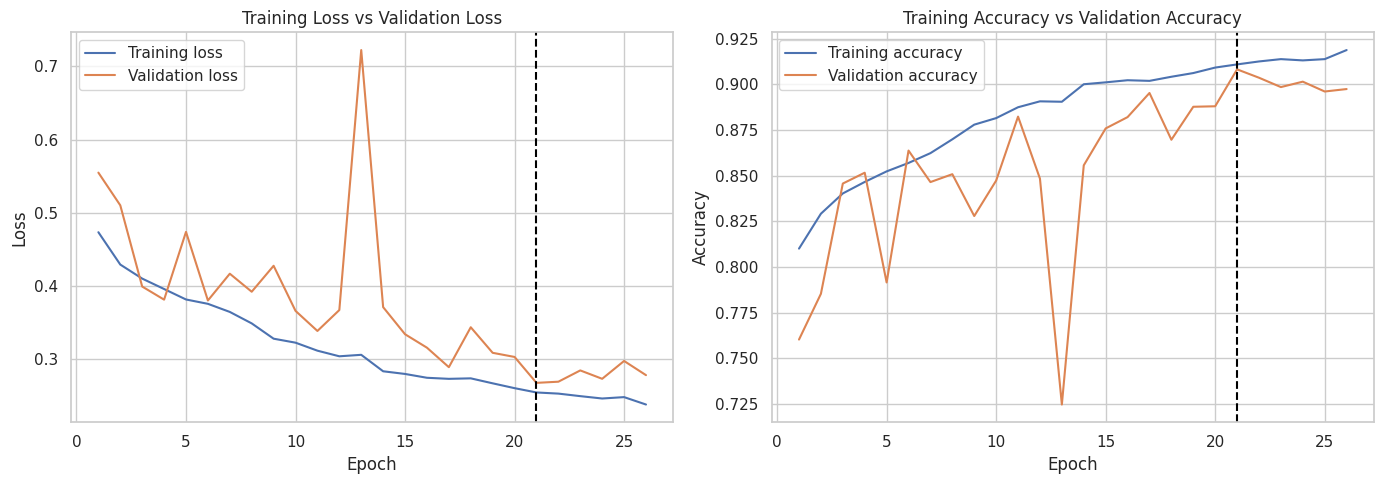

In [10]:
ep=np.arange(1,len(h["loss"])+1)
fig,ax=plt.subplots(1,2,figsize=(14,5))
ax[0].plot(ep,h["loss"],label="Training loss");ax[0].plot(ep,h["val_loss"],label="Validation loss");ax[0].axvline(chosen["best"],ls="--",color="black");ax[0].set(title="Training Loss vs Validation Loss",xlabel="Epoch",ylabel="Loss");ax[0].legend()
ax[1].plot(ep,h["accuracy"],label="Training accuracy");ax[1].plot(ep,h["val_accuracy"],label="Validation accuracy");ax[1].axvline(chosen["best"],ls="--",color="black");ax[1].set(title="Training Accuracy vs Validation Accuracy",xlabel="Epoch",ylabel="Accuracy");ax[1].legend()
plt.tight_layout()
import os; os.makedirs("results", exist_ok=True); os.makedirs("figures", exist_ok=True)
plt.savefig("results/training_curve.png", dpi=200, bbox_inches="tight")
plt.savefig("figures/training_curves.png", dpi=200, bbox_inches="tight"); plt.show()

## 21. Final Test Evaluation
All experiments are evaluated once after selection only for final reporting; test outcomes never choose a model.

## 22. Precision / Recall / F1 Score

In [11]:
truth=test_df.class_id.to_numpy();comparison=[]
for name in specs:
 model=build(*specs[name]);model.set_weights(runs[name]["weights"]);loss,acc=model.evaluate(test_ds,verbose=0);pred=np.argmax(model.predict(test_ds,verbose=0),axis=1)
 row={"Model":name,"Training Accuracy":runs[name]["h"]["accuracy"][-1],"Validation Accuracy":runs[name]["h"]["val_accuracy"][-1],"Test Accuracy":acc,"Test Loss":loss,
 "Precision":precision_score(truth,pred,average="macro",zero_division=0),"Recall":recall_score(truth,pred,average="macro",zero_division=0),"F1 Score":f1_score(truth,pred,average="macro",zero_division=0)}
 comparison.append(row)
 if name==best_name:test_loss,test_accuracy,y_pred=loss,acc,pred
print("Final Test Loss:",test_loss);print("Final Test Accuracy:",test_accuracy)
metrics={"Accuracy":accuracy_score(truth,y_pred),"Macro Precision":precision_score(truth,y_pred,average="macro",zero_division=0),"Macro Recall":recall_score(truth,y_pred,average="macro",zero_division=0),"Macro F1":f1_score(truth,y_pred,average="macro",zero_division=0),"Weighted Precision":precision_score(truth,y_pred,average="weighted",zero_division=0),"Weighted Recall":recall_score(truth,y_pred,average="weighted",zero_division=0),"Weighted F1":f1_score(truth,y_pred,average="weighted",zero_division=0)}
display(pd.DataFrame(metrics.items(),columns=["Metric","Value"]));print(classification_report(truth,y_pred,target_names=class_names,zero_division=0))

Final Test Loss: 0.2704969346523285
Final Test Accuracy: 0.9050188660621643


,Metric,Value
0,Accuracy,0.905019
1,Macro Precision,0.903147
2,Macro Recall,0.904291
3,Macro F1,0.903686
4,Weighted Precision,0.905218
5,Weighted Recall,0.905019
6,Weighted F1,0.905086


              precision    recall  f1-score   support

     organic       0.92      0.91      0.92      2082
  recyclable       0.89      0.90      0.89      1624

    accuracy                           0.91      3706
   macro avg       0.90      0.90      0.90      3706
weighted avg       0.91      0.91      0.91      3706



## 23. Confusion Matrix
Graph 4 has actual labels on rows and predictions on columns, and reports the largest measured confusion.

## 24. Metrics Comparison
Graph 5 compares accuracy, macro precision, macro recall, and macro F1.

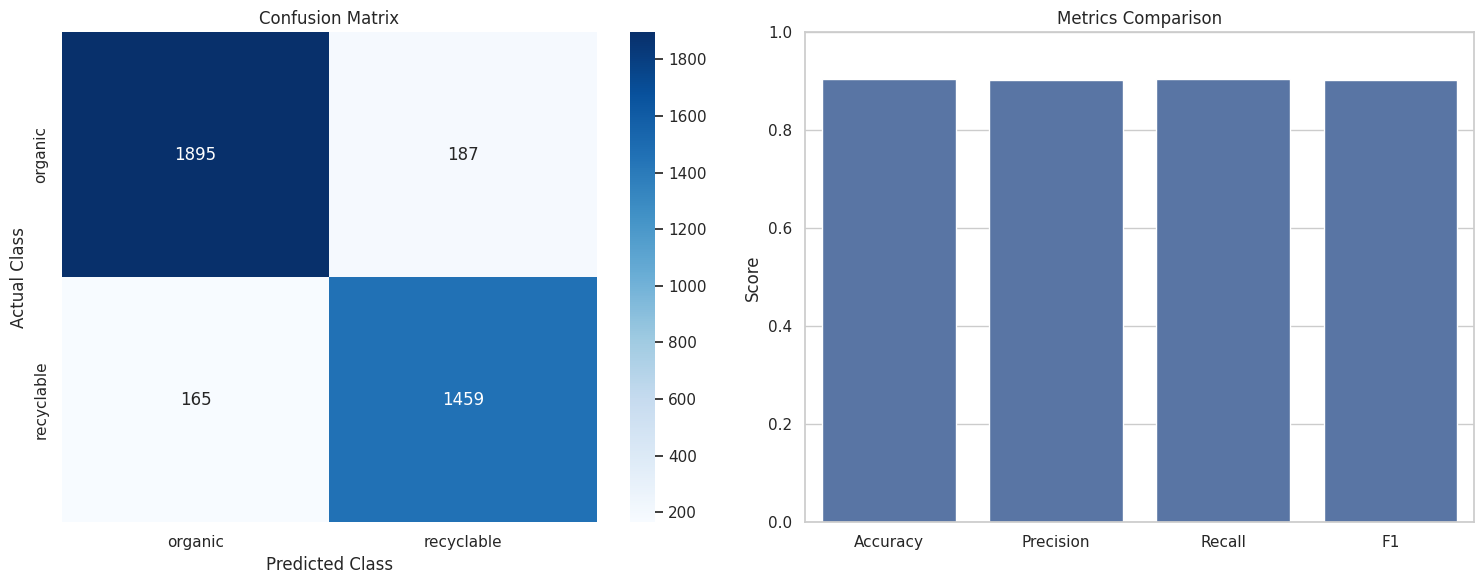

Largest confusion: organic as recyclable 187


In [12]:
cm=confusion_matrix(truth,y_pred,labels=np.arange(len(class_names)))
fig,ax=plt.subplots(1,2,figsize=(15,6));sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=class_names,yticklabels=class_names,ax=ax[0]);ax[0].set(title="Confusion Matrix",xlabel="Predicted Class",ylabel="Actual Class")
plot={"Accuracy":metrics["Accuracy"],"Precision":metrics["Macro Precision"],"Recall":metrics["Macro Recall"],"F1":metrics["Macro F1"]}
sns.barplot(x=list(plot),y=list(plot.values()),ax=ax[1]);ax[1].set(ylim=(0,1),title="Metrics Comparison",ylabel="Score")
plt.tight_layout()
import os; os.makedirs("results", exist_ok=True); plt.savefig("results/confusion_matrix.png", dpi=200, bbox_inches="tight"); os.makedirs("figures", exist_ok=True); plt.savefig("figures/confusion_matrix.png", dpi=200, bbox_inches="tight"); plt.show()
off=cm.copy();np.fill_diagonal(off,0)
if off.max():a,p=np.unravel_index(np.argmax(off),off.shape);print("Largest confusion:",class_names[a],"as",class_names[p],off[a,p])
from sklearn.metrics import roc_curve, roc_auc_score
best_model = build(*specs[best_name])
best_model.set_weights(runs[best_name]["weights"])
probs = best_model.predict(test_ds, verbose=0)
p1 = probs[:, 1] if probs.ndim == 2 else probs.reshape(-1)
fpr, tpr, _ = roc_curve(truth, p1)
auc_val = roc_auc_score(truth, p1)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"{best_name} (AUC = {auc_val:.4f})", color="darkorange")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve: {best_name}"); plt.legend(); plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/roc_curve.png", dpi=200, bbox_inches="tight")
plt.close()


## 25. 5-Fold Cross Validation
Stratified 5-fold CV operates only on the development portion. Every fold uses a new selected-architecture CNN and EarlyStopping.

## 26. Cross Validation Results

Fold 1 Accuracy: 0.8879
Fold 2 Accuracy: 0.8990
Fold 3 Accuracy: 0.8879
Fold 4 Accuracy: 0.9040
Fold 5 Accuracy: 0.8952
Mean CV Accuracy: 0.8948045253753663 Standard Deviation: 0.006326731927047417


,Fold,Validation Accuracy,Validation Loss,Best Epoch
0,1,0.887857,0.313046,11
1,2,0.899048,0.290214,22
2,3,0.887857,0.302290,13
3,4,0.904048,0.286674,12
4,5,0.895213,0.299498,19


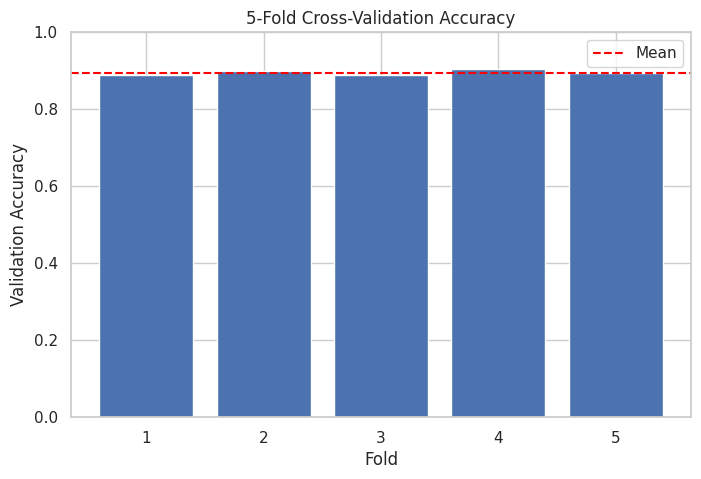

In [13]:
cv=[]
for fold,(ti,vi) in enumerate(StratifiedKFold(5,shuffle=True,random_state=SEED).split(dev_df,dev_df.class_id),1):
 tr,va=dev_df.iloc[ti],dev_df.iloc[vi];fw=None
 if imbalanced:
  w=compute_class_weight("balanced",classes=np.arange(len(class_names)),y=tr.class_id);fw={int(i):float(x) for i,x in enumerate(w)}
 tf.keras.backend.clear_session();model=build(*specs[best_name])
 fh=model.fit(make_ds(tr,True),validation_data=make_ds(va),epochs=EPOCHS,class_weight=fw,callbacks=[EarlyStopping(monitor="val_loss",patience=PATIENCE,restore_best_weights=True),ReduceLROnPlateau(monitor="val_loss",factor=.5,patience=2,min_lr=1e-6)],verbose=0).history
 i=int(np.argmin(fh["val_loss"]));cv.append([fold,fh["val_accuracy"][i],fh["val_loss"][i],i+1]);print("Fold {} Accuracy: {:.4f}".format(fold,fh["val_accuracy"][i]))
cv_df=pd.DataFrame(cv,columns=["Fold","Validation Accuracy","Validation Loss","Best Epoch"]);cv_acc=cv_df["Validation Accuracy"].to_numpy()
print("Mean CV Accuracy:",np.mean(cv_acc),"Standard Deviation:",np.std(cv_acc));display(cv_df)
plt.figure(figsize=(8,5));plt.bar(cv_df.Fold.astype(str),cv_acc);plt.axhline(np.mean(cv_acc),color="red",ls="--",label="Mean");plt.ylim(0,1);plt.title("5-Fold Cross-Validation Accuracy");plt.xlabel("Fold");plt.ylabel("Validation Accuracy");plt.legend();import os; os.makedirs("figures", exist_ok=True); plt.savefig("figures/cross_validation.png", dpi=200, bbox_inches="tight"); plt.show()

## 27. Bias Analysis
This is a practical train-validation-gap diagnostic, not a direct statistical estimate of bias.

## 28. Variance Analysis
CV fold variation measures split sensitivity.

## 29. Overfitting / Underfitting Analysis

In [14]:
i=chosen["best"]-1;tr_acc,va_acc=h["accuracy"][i],h["val_accuracy"][i];gap=tr_acc-va_acc
cv_var=float(np.var(cv_acc));cv_std=float(np.std(cv_acc))
display(pd.DataFrame({"Measure":["Training Accuracy","Validation Accuracy","Train-Validation Gap","CV Mean","CV Variance","CV Standard Deviation"],"Value":[tr_acc,va_acc,gap,np.mean(cv_acc),cv_var,cv_std]}))
if tr_acc<.6 and va_acc<.6 and abs(gap)<.1:fit_note="Possible underfitting: both accuracies are low with a small gap."
elif gap>.15 or (h["accuracy"][-1]>tr_acc and h["val_loss"][-1]>chosen["loss"]):fit_note="Possible overfitting: substantial gap and/or worsening validation loss."
else:fit_note="Reasonably balanced fit by this practical heuristic."
print(fit_note)

,Measure,Value
0,Training Accuracy,0.910999
1,Validation Accuracy,0.908282
2,Train-Validation Gap,0.002718
3,CV Mean,0.894805
4,CV Variance,0.000040
5,CV Standard Deviation,0.006327


Possible overfitting: substantial gap and/or worsening validation loss.


## 30. Early Stopping Analysis

## 31. Regularization Comparison

## 32. Final Results Table

In [15]:
display(pd.DataFrame({"Parameter":["Maximum Epochs","Actual Epochs","Best Epoch","Best Validation Loss","Early Stopping Patience"],"Value":[EPOCHS,chosen["actual"],chosen["best"],chosen["loss"],PATIENCE]}))
comp=pd.DataFrame(comparison);display(comp)
final=pd.DataFrame([{"Model":best_name,"Best Epoch":chosen["best"],"Training Accuracy":tr_acc,"Validation Accuracy":va_acc,"Test Accuracy":test_accuracy,"Test Loss":test_loss,"Precision":metrics["Macro Precision"],"Recall":metrics["Macro Recall"],"F1 Score":metrics["Macro F1"],"5-Fold Mean Accuracy":np.mean(cv_acc),"5-Fold Standard Deviation":cv_std,"5-Fold Variance":cv_var}]);display(final)

,Parameter,Value
0,Maximum Epochs,50.000000
1,Actual Epochs,26.000000
2,Best Epoch,21.000000
3,Best Validation Loss,0.267592
4,Early Stopping Patience,5.000000


,Model,Training Accuracy,Validation Accuracy,Test Accuracy,Test Loss,Precision,Recall,F1 Score
0,Baseline,0.909727,0.896682,0.895575,0.262463,0.893157,0.897104,0.894552
1,Dropout,0.893766,0.867008,0.879115,0.293068,0.878389,0.875547,0.876800
2,L1 / Lasso,0.918864,0.897491,0.905019,0.270497,0.903147,0.904291,0.903686
3,L2 / Ridge,0.920194,0.894254,0.905559,0.265597,0.903277,0.906126,0.904457


,Model,Best Epoch,Training Accuracy,Validation Accuracy,Test Accuracy,Test Loss,Precision,Recall,F1 Score,5-Fold Mean Accuracy,5-Fold Standard Deviation,5-Fold Variance
0,L1 / Lasso,21,0.910999,0.908282,0.905019,0.270497,0.903147,0.904291,0.903686,0.894805,0.006327,0.00004


## 33. Final Conclusion
The following conclusion is created from actual results.

In [16]:
assert 'best_name' in locals(), "'best_name' is not defined. Ensure model training and selection cells have been run."
assert 'test_accuracy' in locals(), "'test_accuracy' is not defined. Ensure evaluation cell has been run."
assert 'metrics' in locals(), "'metrics' is not defined. Ensure evaluation cell has been run."
assert 'cv_acc' in locals(), "'cv_acc' is not defined. Ensure cross-validation cell has been run."
assert 'cv_var' in locals(), "'cv_var' is not defined. Ensure cross-validation analysis cell has been run."
assert 'chosen' in locals(), "'chosen' is not defined. Ensure model training cell has been run."
assert 'stopped' in locals(), "'stopped' is not defined. Ensure model training cell has been run."
assert 'fit_note' in locals(), "'fit_note' is not defined. Ensure fit diagnostic cell has been run."
assert 'va_acc' in locals(), "'va_acc' is not defined. Ensure diagnostic cell has been run."
assert 'comp' in locals(), "'comp' is not defined. Ensure comparison cell has been run."

print("Selected model:", best_name)
print("Test accuracy, precision, recall, F1:", test_accuracy, metrics["Macro Precision"], metrics["Macro Recall"], metrics["Macro F1"])
print("Balanced?", not imbalanced, "Class weights used?", cw is not None)
print("CV mean, variance:", np.mean(cv_acc), cv_var)
print("Early stopping", "occurred" if stopped else "did not occur", "at epoch:", chosen["actual"], "Best epoch:", chosen["best"])
print("Fit diagnostic:", fit_note)
print("The simple CNN is", "a reasonable starting point" if va_acc >= 0.60 else "not yet sufficient as a strong baseline", "at the observed validation accuracy.")
for _, r in comp.iterrows():
    print(r["Model"], "validation accuracy:", round(r["Validation Accuracy"], 4), "test accuracy:", round(r["Test Accuracy"], 4))
print("The rows above state the actual observed Baseline, Dropout, L1/Lasso, and L2/Ridge effects; the best validation model is", best_name)


Selected model: L1 / Lasso
Test accuracy, precision, recall, F1: 0.9050188660621643 0.9031468112104323 0.9042907409419163 0.9036861536767575
Balanced? True Class weights used? False
CV mean, variance: 0.8948045254000492 4.002753696803274e-05
Early stopping occurred at epoch: 26 Best epoch: 21
Fit diagnostic: Possible overfitting: substantial gap and/or worsening validation loss.
The simple CNN is a reasonable starting point at the observed validation accuracy.
Baseline validation accuracy: 0.8967 test accuracy: 0.8956
Dropout validation accuracy: 0.867 test accuracy: 0.8791
L1 / Lasso validation accuracy: 0.8975 test accuracy: 0.905
L2 / Ridge validation accuracy: 0.8943 test accuracy: 0.9056
The rows above state the actual observed Baseline, Dropout, L1/Lasso, and L2/Ridge effects; the best validation model is L1 / Lasso


## 34. Limitations and Future Work
Performance depends on label quality, image quality, visual similarity, and data volume. Future work: obtain more balanced data, inspect mistakes, tune using validation only, test on independently collected images, and consider more advanced architectures only if this simple baseline is insufficient.